# AI-readiness and African industrialisation: reproducible analysis pipeline
Revised workflow: (1) robust World Bank download, (2) data audit and fixed-sample construction,
(3) descriptive figures, (4) two-way fixed-effects regressions with country-clustered errors,
(5) chronological out-of-sample prediction benchmark, (6) scenario-matrix placement.
Everything is written to `results/`. Set `SYNTHETIC=1` only to smoke-test the code; never for the paper.

In [1]:
!pip install -q pandas numpy requests matplotlib seaborn scikit-learn xgboost shap statsmodels
import os, warnings, json
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt, seaborn as sns
from functools import reduce
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
import statsmodels.formula.api as smf
warnings.filterwarnings("ignore")
os.makedirs("results", exist_ok=True)
RS = 42
SYNTHETIC = os.environ.get("SYNTHETIC") == "1"
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False})
C1, C2, C3, C4 = "#1f4e79", "#c0504d", "#2e8b57", "#7f7f7f"


## 1. Configuration

In [2]:
countries = ("DZA AGO BEN BWA BFA BDI CPV CMR CAF TCD COM COG COD CIV DJI EGY GNQ ERI SWZ ETH GAB GMB GHA GIN GNB "
             "KEN LSO LBR LBY MDG MWI MLI MRT MUS MAR MOZ NAM NER NGA RWA STP SEN SYC SLE SOM ZAF SSD SDN TZA TGO "
             "TUN UGA ZMB ZWE").split()
assert len(countries) == 54
SMALL_ISLANDS = ["SYC", "STP", "CPV", "COM", "MUS"]
START, END = 2000, 2024
indicators = {
    "manufacturing": "NV.IND.MANF.ZS", "internet": "IT.NET.USER.ZS", "broadband": "IT.NET.BBND.P2",
    "mobile": "IT.CEL.SETS.P2", "electricity": "EG.ELC.ACCS.ZS", "research_gdp": "GB.XPD.RSDV.GD.ZS",
    "scientific_articles": "IP.JRN.ARTC.SC", "gdp_per_capita": "NY.GDP.PCAP.KD", "tertiary_education": "SE.TER.ENRR",
    "fdi": "BX.KLT.DINV.WD.GD.ZS", "trade": "NE.TRD.GNFS.ZS", "capital_formation": "NE.GDI.TOTL.ZS",
    "renewable_energy": "EG.FEC.RNEW.ZS", "unemployment": "SL.UEM.TOTL.ZS",
    # added in the revision: levels for weighting and per-capita output
    "mva_const": "NV.IND.MANF.KD", "gdp_const": "NY.GDP.MKTP.KD", "population": "SP.POP.TOTL",
}
# Governance (WGI). The original run failed with source=3; try both code styles, with and without a source id.
wgi = {"regulatory_quality": ["GOV_WGI_RQ.EST", "RQ.EST"], "government_effectiveness": ["GOV_WGI_GE.EST", "GE.EST"]}


## 2. Download (paginated, retried, logged)

In [3]:
session = requests.Session()
session.mount("https://", HTTPAdapter(max_retries=Retry(total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])))
API = "https://api.worldbank.org/v2"

def fetch(code, source=None):
    url = f"{API}/country/{';'.join(countries)}/indicator/{code}"
    rows, page = [], 1
    while True:
        p = {"format": "json", "date": f"{START}:{END}", "per_page": 5000, "page": page}
        if source: p["source"] = source
        r = session.get(url, params=p, timeout=120); r.raise_for_status()
        js = r.json()
        if not isinstance(js, list) or len(js) < 2 or not js[1]:
            break
        rows += js[1]
        if page >= js[0].get("pages", 1): break
        page += 1
    return rows

def to_frame(rows, name):
    df = pd.DataFrame([{"country": x["countryiso3code"], "year": int(x["date"]), name: x["value"]} for x in rows])
    return df[df.country.isin(countries)].drop_duplicates(["country", "year"])

def synthetic_panel():
    rng = np.random.default_rng(RS); rec = []
    for c in countries:
        base = rng.uniform(4, 20); g = rng.normal(0, .05); gdp0 = rng.uniform(500, 8000)
        for y in range(START, END + 1):
            t = y - START
            rec.append(dict(country=c, year=y,
                manufacturing=max(1, base + g * t + rng.normal(0, .8)),
                internet=min(95, .2 + t * rng.uniform(.5, 2.5) + rng.normal(0, 1)),
                broadband=max(0, t * rng.uniform(0, .3)), mobile=min(150, t * rng.uniform(1, 5) + rng.normal(0, 3)),
                electricity=min(100, rng.uniform(10, 60) + t * rng.uniform(.2, 1.5)), research_gdp=rng.uniform(.05, 1) if rng.random() < .2 else np.nan,
                scientific_articles=abs(rng.normal(300, 200)) * (1 + t / 10), gdp_per_capita=gdp0 * (1 + .02 * t) * np.exp(rng.normal(0, .03)),
                tertiary_education=rng.uniform(1, 40) if rng.random() < .55 else np.nan, fdi=rng.normal(3, 4),
                trade=rng.uniform(30, 120), capital_formation=rng.uniform(10, 40), renewable_energy=rng.uniform(5, 90),
                unemployment=rng.uniform(1, 25), mva_const=np.nan, gdp_const=np.nan, population=rng.uniform(1e5, 1e8)))
    d = pd.DataFrame(rec); d["gdp_const"] = d.gdp_per_capita * d.population; d["mva_const"] = d.gdp_const * d.manufacturing / 100
    for k in ["manufacturing", "trade", "capital_formation", "renewable_energy"]:
        d.loc[rng.random(len(d)) < .12, k] = np.nan
    for g in wgi: d[g] = rng.normal(-.7, .6, len(d))
    return d, pd.DataFrame({"country": countries, "income": rng.choice(["Low income", "Lower middle income", "Upper middle income"], 54)})

log = []
if SYNTHETIC:
    df, meta = synthetic_panel()
else:
    frames = []
    for name, code in indicators.items():
        try:
            frames.append(to_frame(fetch(code), name)); log.append((name, code, "ok"))
        except Exception as e:
            log.append((name, code, f"FAILED: {e}"))
    for name, codes in wgi.items():
        got = False
        for code in codes:
            for src in (3, None):
                try:
                    rows = fetch(code, src)
                    if rows: frames.append(to_frame(rows, name)); log.append((name, f"{code} src={src}", "ok")); got = True; break
                except Exception: pass
            if got: break
        if not got: log.append((name, "|".join(codes), "FAILED (not retrievable from WDI API; download WGI csv from info.worldbank.org/governance/wgi and merge)"))
    df = reduce(lambda a, b: a.merge(b, on=["country", "year"], how="outer"), frames)
    m = requests.get(f"{API}/country/{';'.join(countries)}", params={"format": "json", "per_page": 500}, timeout=60).json()[1]
    meta = pd.DataFrame([{"country": x["id"], "income": x["incomeLevel"]["value"], "region": x["region"]["value"]} for x in m])
pd.DataFrame(log, columns=["indicator", "code", "status"]).to_csv("results/download_log.csv", index=False)
df = df.sort_values(["country", "year"]).reset_index(drop=True)
df = df.merge(meta, on="country", how="left")
df.to_csv("results/africa_panel_raw.csv", index=False)
print(pd.DataFrame(log, columns=["indicator", "code", "status"]).to_string(index=False))
print("Panel:", df.shape, "| countries:", df.country.nunique())


               indicator                 code status
           manufacturing       NV.IND.MANF.ZS     ok
                internet       IT.NET.USER.ZS     ok
               broadband       IT.NET.BBND.P2     ok
                  mobile       IT.CEL.SETS.P2     ok
             electricity       EG.ELC.ACCS.ZS     ok
            research_gdp    GB.XPD.RSDV.GD.ZS     ok
     scientific_articles       IP.JRN.ARTC.SC     ok
          gdp_per_capita       NY.GDP.PCAP.KD     ok
      tertiary_education          SE.TER.ENRR     ok
                     fdi BX.KLT.DINV.WD.GD.ZS     ok
                   trade       NE.TRD.GNFS.ZS     ok
       capital_formation       NE.GDI.TOTL.ZS     ok
        renewable_energy       EG.FEC.RNEW.ZS     ok
            unemployment       SL.UEM.TOTL.ZS     ok
               mva_const       NV.IND.MANF.KD     ok
               gdp_const       NY.GDP.MKTP.KD     ok
              population          SP.POP.TOTL     ok
      regulatory_quality GOV_WGI_RQ.EST src=3 

## 3. Data audit and sample construction

In [4]:
ind_cols = [c for c in df.columns if c in list(indicators) + list(wgi)]
audit = pd.DataFrame({"observed": df[ind_cols].notna().sum(), "missing_pct": df[ind_cols].isna().mean() * 100}).sort_values("missing_pct", ascending=False)
audit.round(2).to_csv("results/table1_coverage.csv"); print(audit.round(2))

# country coverage of the outcome
cov = df.groupby("country").manufacturing.apply(lambda s: s.notna().sum())
core = cov[cov >= 20].index.tolist()                      # >=20 of 25 years observed
early = df[df.year.between(2000, 2004)].groupby("country").manufacturing.apply(lambda s: s.notna().any())
late = df[df.year.between(2020, 2024)].groupby("country").manufacturing.apply(lambda s: s.notna().any())
fixed = [c for c in core if early.get(c, False) and late.get(c, False)]   # fixed sample for trend analysis
print(f"countries with outcome data: {(cov>0).sum()}; core (>=20 yrs): {len(core)}; fixed trend sample: {len(fixed)}")
json.dump({"n_records": int(len(df)), "n_manufacturing_obs": int(df.manufacturing.notna().sum()),
           "n_core": len(core), "core": core, "n_fixed": len(fixed), "fixed": fixed}, open("results/sample_definition.json", "w"), indent=1)

# transformations
d = df.copy()
d["ln_gdppc"] = np.log(d.gdp_per_capita); d["ln_gdppc_sq"] = d.ln_gdppc ** 2
d["ln_articles"] = np.log1p(d.scientific_articles); d["ln_pop"] = np.log(d.population)
d["mva_pc"] = d.mva_const / d.population
# winsorise predictors at 1/99 (outcome left untouched)
for c in ["internet", "mobile", "broadband", "electricity", "fdi", "trade", "capital_formation", "renewable_energy", "unemployment", "ln_articles"]:
    lo, hi = d[c].quantile([.01, .99]); d[c] = d[c].clip(lo, hi)
# digital-readiness index: first principal component of internet use and mobile subscriptions
dr = d[["internet", "mobile"]].dropna(); Z = StandardScaler().fit(dr); pca = PCA(1, random_state=RS).fit(Z.transform(dr))
d["digital_idx"] = np.nan
d.loc[dr.index, "digital_idx"] = pca.transform(Z.transform(dr))[:, 0] * np.sign(pca.components_[0].sum())
print("digital index explained variance:", round(pca.explained_variance_ratio_[0], 3))
# multicollinearity diagnostics on the regression regressors
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_cols = ["internet", "mobile", "electricity", "ln_gdppc", "trade", "fdi", "capital_formation", "renewable_energy", "unemployment"]
V = d[vif_cols].dropna(); Vz = (V - V.mean()) / V.std()
vif = pd.Series([variance_inflation_factor(Vz.values, i) for i in range(Vz.shape[1])], index=vif_cols).round(2)
vif.to_csv("results/table_vif.csv"); print("VIF:\n", vif)


                          observed  missing_pct
research_gdp                   227        83.19
tertiary_education             715        47.04
broadband                      998        26.07
mva_const                     1108        17.93
capital_formation             1150        14.81
trade                         1156        14.37
manufacturing                 1172        13.19
renewable_energy              1200        11.11
government_effectiveness      1285         4.81
regulatory_quality            1286         4.74
scientific_articles           1296         4.00
internet                      1297         3.93
fdi                           1305         3.33
mobile                        1307         3.19
gdp_per_capita                1307         3.19
gdp_const                     1307         3.19
unemployment                  1322         2.07
electricity                   1334         1.19
population                    1350         0.00
countries with outcome data: 53; core (>

## 4. Descriptive figures

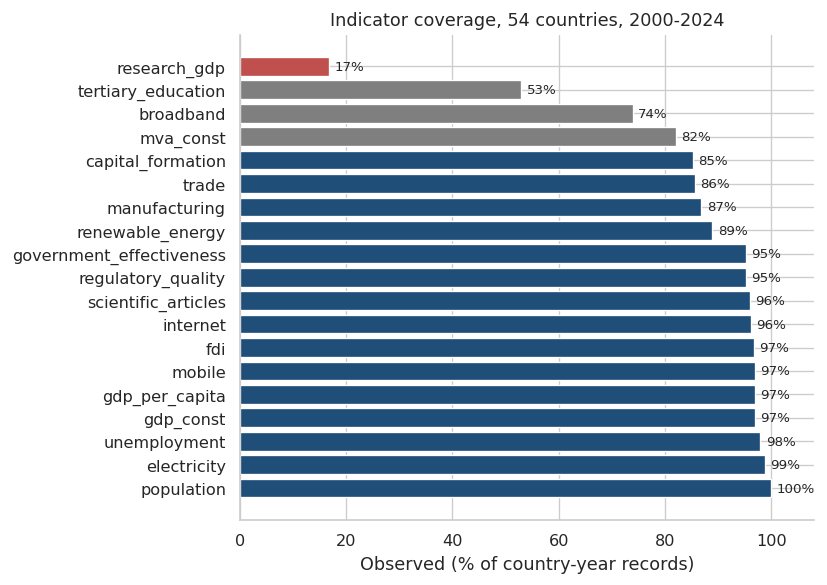

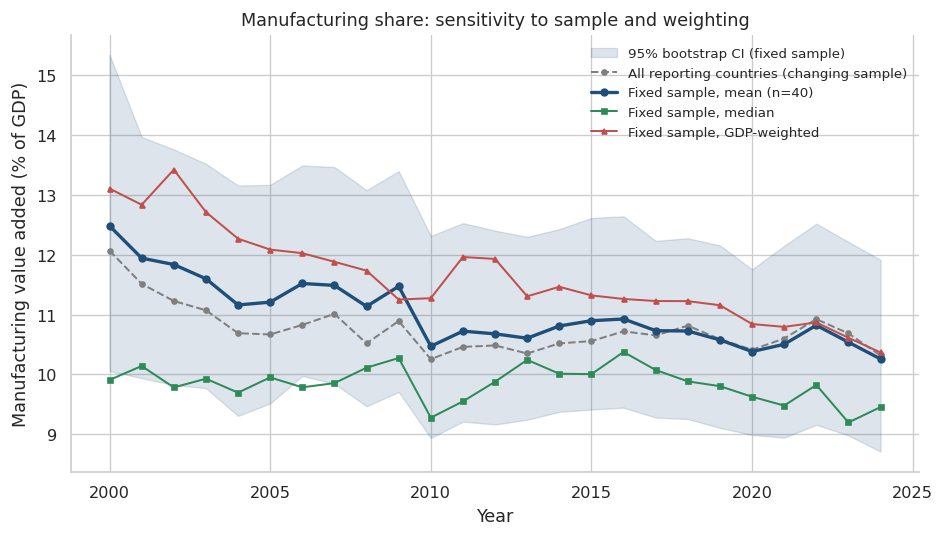

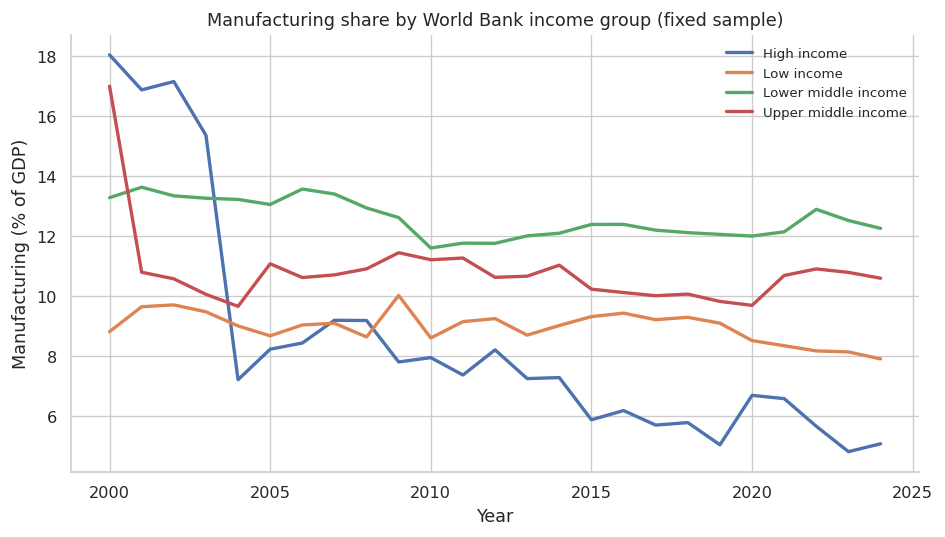

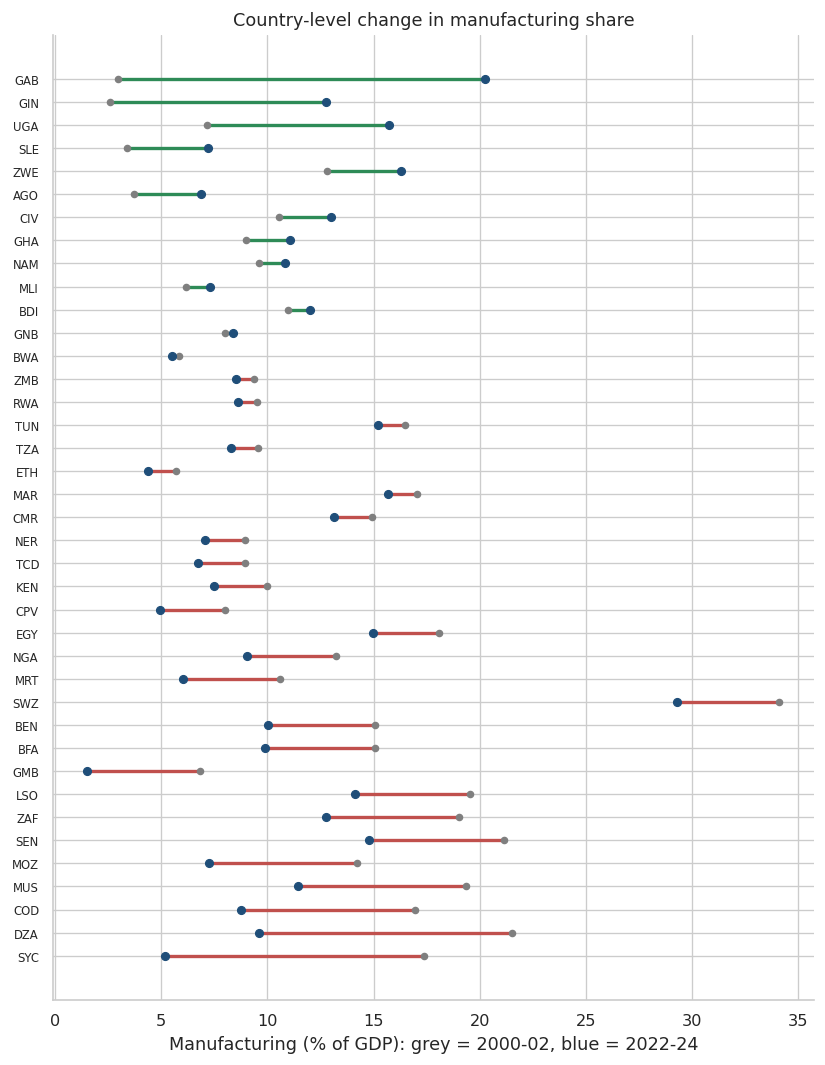

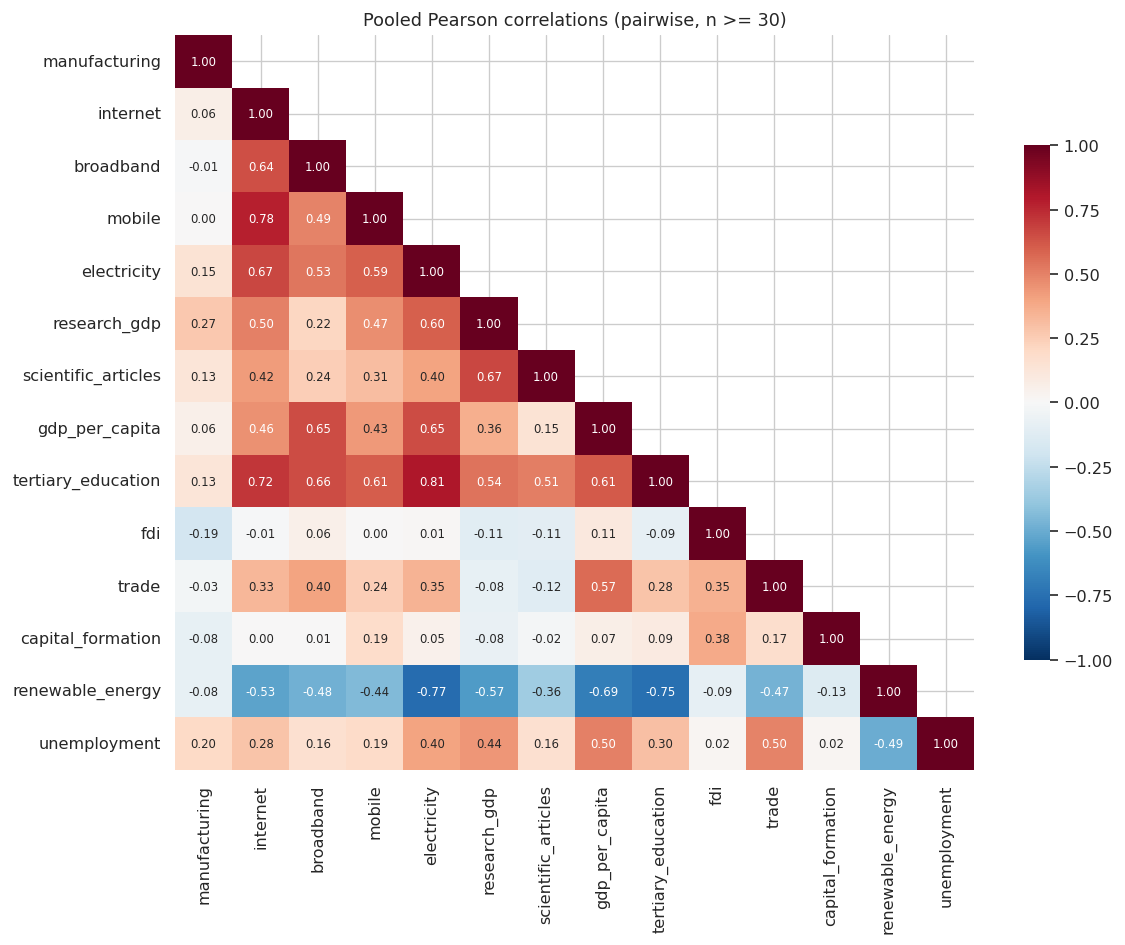

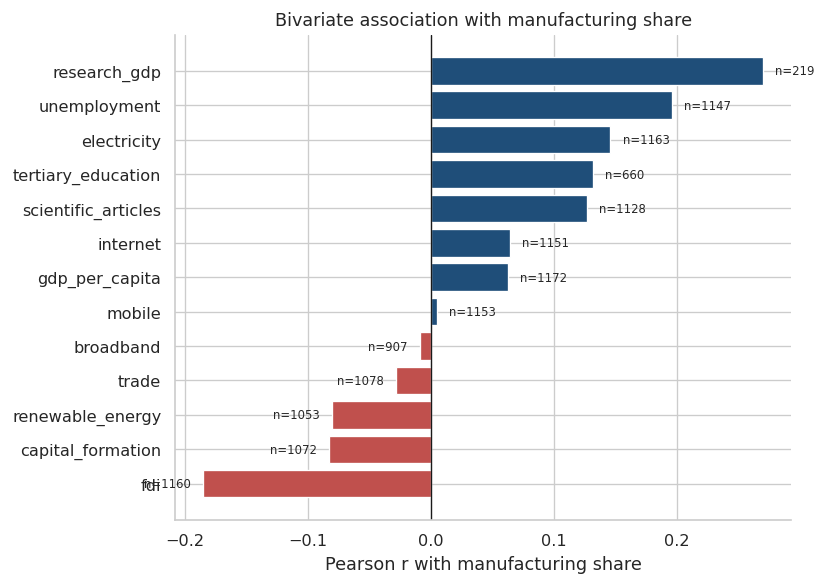

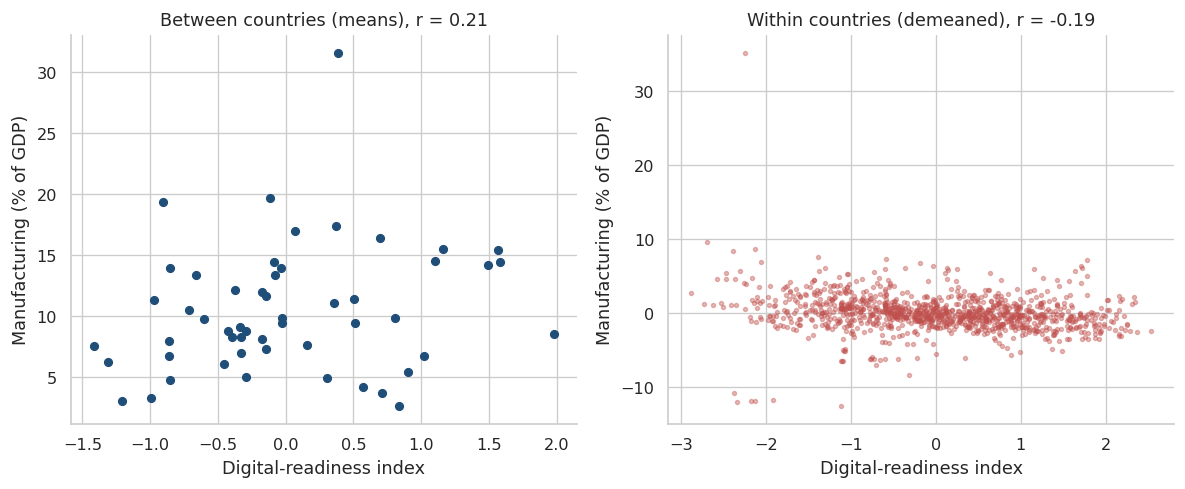

In [5]:
# Fig 1: coverage
fig, ax = plt.subplots(figsize=(7, 5))
a = audit.sort_values("missing_pct")
ax.barh(a.index, 100 - a.missing_pct, color=[C1 if v >= 85 else (C4 if v >= 50 else C2) for v in 100 - a.missing_pct])
for i, v in enumerate(100 - a.missing_pct): ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8)
ax.set_xlim(0, 108); ax.set_xlabel("Observed (% of country-year records)"); ax.set_title("Indicator coverage, 54 countries, 2000-2024")
plt.tight_layout(); plt.savefig("results/fig1_coverage.png"); plt.show()

# Fig 2: manufacturing trend - four ways to compute it
def boot_ci(sub, n=500):
    rng = np.random.default_rng(RS); piv = sub.pivot(index="year", columns="country", values="manufacturing")
    out = []
    for _ in range(n):
        cs = rng.choice(piv.columns, len(piv.columns)); out.append(piv[cs].mean(axis=1).values)
    return np.nanpercentile(out, [2.5, 97.5], axis=0), piv.index
unb = d.groupby("year").manufacturing.mean()
fx = d[d.country.isin(fixed)]; fxm = fx.groupby("year").manufacturing.mean()
med = fx.groupby("year").manufacturing.median()
w = fx.dropna(subset=["mva_const", "gdp_const"]).groupby("year").apply(lambda g: g.mva_const.sum() / g.gdp_const.sum() * 100)
ci, yrs = boot_ci(fx)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.fill_between(yrs, ci[0], ci[1], color=C1, alpha=.15, label="95% bootstrap CI (fixed sample)")
ax.plot(unb.index, unb.values, color=C4, ls="--", marker="o", ms=3, label="All reporting countries (changing sample)")
ax.plot(fxm.index, fxm.values, color=C1, marker="o", ms=4, lw=2, label=f"Fixed sample, mean (n={len(fixed)})")
ax.plot(med.index, med.values, color=C3, marker="s", ms=3, label="Fixed sample, median")
if len(w): ax.plot(w.index, w.values, color=C2, marker="^", ms=3, label="Fixed sample, GDP-weighted")
ax.set_xlabel("Year"); ax.set_ylabel("Manufacturing value added (% of GDP)"); ax.set_title("Manufacturing share: sensitivity to sample and weighting")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.savefig("results/fig2_trend_sensitivity.png"); plt.show()
pd.DataFrame({"unbalanced_mean": unb, "fixed_mean": fxm, "fixed_median": med, "fixed_gdp_weighted": w}).round(3).to_csv("results/table_trend_series.csv")

# Fig 3: by income group
g = d[d.country.isin(fixed)].groupby(["income", "year"]).manufacturing.mean().unstack(0)
fig, ax = plt.subplots(figsize=(8, 4.6)); g.plot(ax=ax, lw=2); ax.set_ylabel("Manufacturing (% of GDP)"); ax.set_xlabel("Year")
ax.set_title("Manufacturing share by World Bank income group (fixed sample)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("results/fig3_trend_income.png"); plt.show()

# Fig 4: country change, first vs last 3-year average (dumbbell)
def avg(c, a, b): return d[(d.country == c) & d.year.between(a, b)].manufacturing.mean()
ch = pd.DataFrame({"c": fixed, "start": [avg(c, 2000, 2002) for c in fixed], "end": [avg(c, 2022, 2024) for c in fixed]}).dropna()
ch["delta"] = ch.end - ch.start; ch = ch.sort_values("delta"); ch.round(2).to_csv("results/table_country_change.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 9))
for i, r in enumerate(ch.itertuples()):
    ax.plot([r.start, r.end], [i, i], color=C3 if r.delta > 0 else C2, lw=2); ax.scatter([r.start], [i], color=C4, s=14, zorder=3); ax.scatter([r.end], [i], color=C1, s=22, zorder=3)
ax.set_yticks(range(len(ch))); ax.set_yticklabels(ch.c, fontsize=7); ax.set_xlabel("Manufacturing (% of GDP): grey = 2000-02, blue = 2022-24")
ax.set_title("Country-level change in manufacturing share"); plt.tight_layout(); plt.savefig("results/fig4_country_change.png"); plt.show()

# Fig 5: correlation heatmap (lower triangle) and the manufacturing row with sample sizes
num = d[[c for c in list(indicators)[:14] if c in d.columns]]
cor = num.corr(min_periods=30); mask = np.triu(np.ones_like(cor, bool), 1)
fig, ax = plt.subplots(figsize=(10, 8)); sns.heatmap(cor, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Pooled Pearson correlations (pairwise, n >= 30)"); plt.tight_layout(); plt.savefig("results/fig5_correlation_heatmap.png"); plt.show()
cor.round(3).to_csv("results/table_correlation_matrix.csv")
mc = cor["manufacturing"].drop("manufacturing"); n_pair = {c: int(num[["manufacturing", c]].dropna().shape[0]) for c in mc.index}
mc = mc.sort_values(); fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(mc.index, mc.values, color=[C1 if v > 0 else C2 for v in mc.values]); ax.axvline(0, color="k", lw=.8)
for i, (k, v) in enumerate(mc.items()): ax.text(v + (.01 if v >= 0 else -.01), i, f"n={n_pair[k]}", va="center", ha="left" if v >= 0 else "right", fontsize=7)
ax.set_xlabel("Pearson r with manufacturing share"); ax.set_title("Bivariate association with manufacturing share"); plt.tight_layout(); plt.savefig("results/fig6_manufacturing_correlations.png"); plt.show()

# Fig 7: between vs within (pooled correlation conflates the two)
s = d[["country", "year", "manufacturing", "digital_idx"]].dropna()
bt = s.groupby("country")[["manufacturing", "digital_idx"]].mean(); wt = s.copy()
for c in ["manufacturing", "digital_idx"]: wt[c] = s[c] - s.groupby("country")[c].transform("mean")
rb, rw = bt.corr().iloc[0, 1], wt[["manufacturing", "digital_idx"]].corr().iloc[0, 1]
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
ax[0].scatter(bt.digital_idx, bt.manufacturing, color=C1, s=22); ax[0].set_title(f"Between countries (means), r = {rb:.2f}")
ax[1].scatter(wt.digital_idx, wt.manufacturing, color=C2, s=6, alpha=.4); ax[1].set_title(f"Within countries (demeaned), r = {rw:.2f}")
for a_ in ax: a_.set_xlabel("Digital-readiness index"); a_.set_ylabel("Manufacturing (% of GDP)")
plt.tight_layout(); plt.savefig("results/fig7_between_within.png"); plt.show()
pd.Series({"between_r": rb, "within_r": rw, "pooled_r": s[["manufacturing", "digital_idx"]].corr().iloc[0, 1]}).round(3).to_csv("results/table_between_within.csv")


## 5. Two-way fixed-effects regressions (country and year effects, country-clustered SEs)
Regressors are standardised (per 1 SD) and lagged one year to limit simultaneity.

                   coef     se      p                   model  n_obs
digital_idx_z_l1 -0.373  0.838  0.656              M1 Digital   1100
digital_idx_z_l1 -0.371  0.847  0.661        M2 + Electricity   1091
electricity_z_l1 -0.583  0.860  0.497        M2 + Electricity   1091
digital_idx_z_l1  0.465  0.943  0.622     M3 + Macro controls    982
electricity_z_l1  0.369  0.718  0.607     M3 + Macro controls    982
digital_idx_z_l1  0.533  0.998  0.593  M4 + Knowledge, labour    959
electricity_z_l1  0.291  0.722  0.687  M4 + Knowledge, labour    959
digital_idx_z_l3  0.518  0.771  0.501          R1 3-year lags    880
electricity_z_l3 -0.051  0.708  0.943          R1 3-year lags    880
digital_idx_z_l1  0.476  1.022  0.642  R2 excl. small islands    885
electricity_z_l1  0.062  0.754  0.935  R2 excl. small islands    885
digital_idx_z_l1  0.666  1.021  0.514        R3 excl. 2020-21    871
electricity_z_l1  0.204  0.688  0.767        R3 excl. 2020-21    871


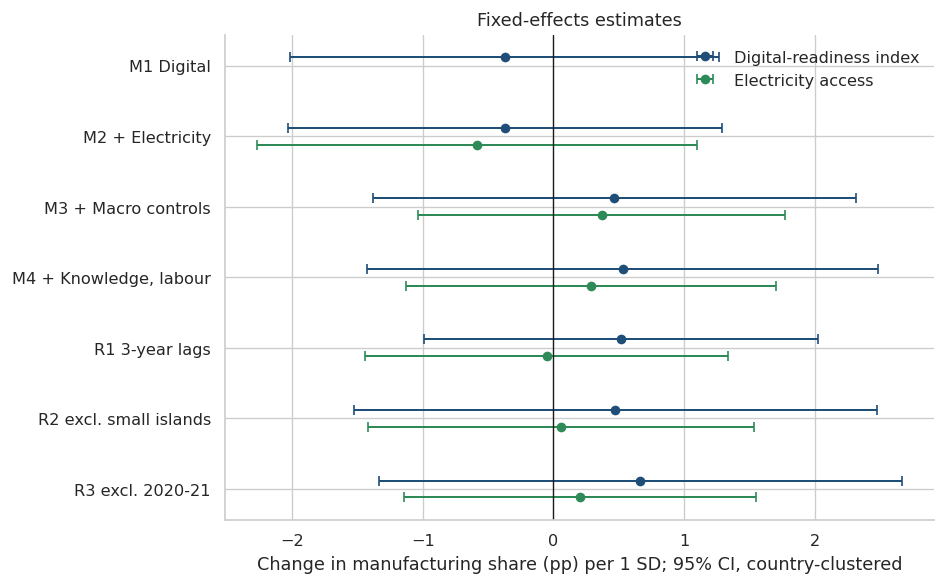

In [6]:
P = d.sort_values(["country", "year"]).copy()
Xs = ["digital_idx", "electricity", "ln_gdppc", "ln_gdppc_sq", "trade", "fdi", "capital_formation", "ln_articles", "unemployment"]
for c in Xs: P[c + "_z"] = (P[c] - P[c].mean()) / P[c].std()
P["ln_gdppc_sq_z"] = P["ln_gdppc_z"] ** 2   # square of the standardised log income, keeps the hump interpretable
def lag(df_, cols, k): return df_.groupby("country")[cols].shift(k)
zc = [c + "_z" for c in Xs]
for k in (1, 3): P[[f"{c}_l{k}" for c in zc]] = lag(P, zc, k).values
P["d_manuf"] = P.groupby("country").manufacturing.diff()
P[[f"{c}_d1" for c in zc]] = P.groupby("country")[zc].diff().shift(1).values

def fe(formula, data, label):
    cols = [t.strip() for t in formula.split("~")[1].split("+")] + ["manufacturing"]; dd = data.dropna(subset=cols + ["country"])
    m = smf.ols(formula + " + C(country) + C(year)", data=dd).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(dd.country)[0]})
    keep = [p for p in m.params.index if not p.startswith("C(") and p != "Intercept"]
    out = pd.DataFrame({"coef": m.params[keep], "se": m.bse[keep], "p": m.pvalues[keep], "model": label})
    out["lo"], out["hi"] = out.coef - 1.96 * out.se, out.coef + 1.96 * out.se
    out["n_obs"], out["n_countries"], out["r2_within_proxy"] = int(m.nobs), dd.country.nunique(), round(m.rsquared, 3)
    return out

L = lambda names, k=1: " + ".join(f"{n}_z_l{k}" for n in names)
specs = {
    "M1 Digital": (f"manufacturing ~ {L(['digital_idx'])}", P),
    "M2 + Electricity": (f"manufacturing ~ {L(['digital_idx','electricity'])}", P),
    "M3 + Macro controls": (f"manufacturing ~ {L(['digital_idx','electricity','ln_gdppc','trade','fdi','capital_formation'])} + ln_gdppc_sq_z_l1", P),
    "M4 + Knowledge, labour": (f"manufacturing ~ {L(['digital_idx','electricity','ln_gdppc','trade','fdi','capital_formation','ln_articles','unemployment'])} + ln_gdppc_sq_z_l1", P),
}
res = [fe(f, dat, lab) for lab, (f, dat) in specs.items()]
# robustness around M4
f4 = specs["M4 + Knowledge, labour"][0]
res.append(fe(f4.replace("_l1", "_l3"), P, "R1 3-year lags"))
res.append(fe(f4, P[~P.country.isin(SMALL_ISLANDS)], "R2 excl. small islands"))
res.append(fe(f4, P[~P.year.isin([2020, 2021])], "R3 excl. 2020-21"))
R = pd.concat(res); R.round(4).to_csv("results/table_fe_regressions.csv"); print(R[R.index.str.startswith(("digital", "electricity"))][["coef", "se", "p", "model", "n_obs"]].round(3))

# coefficient plot for the digital-readiness and electricity terms
sel = R[R.index.isin(["digital_idx_z_l1", "digital_idx_z_l3", "electricity_z_l1", "electricity_z_l3"])].reset_index().rename(columns={"index": "term"})
models = list(dict.fromkeys(R.model)); ypos = {m_: i for i, m_ in enumerate(models)}
fig, ax = plt.subplots(figsize=(8, 5))
for key, col, off, lab in [("digital", C1, -.12, "Digital-readiness index"), ("electricity", C3, .12, "Electricity access")]:
    q = sel[sel.term.str.startswith(key)]
    ax.errorbar(q.coef, [ypos[m_] + off for m_ in q.model], xerr=1.96 * q.se, fmt="o", color=col, capsize=3, label=lab)
ax.axvline(0, color="k", lw=.8); ax.set_yticks(range(len(models))); ax.set_yticklabels(models); ax.invert_yaxis(); ax.legend(frameon=False)
ax.set_xlabel("Change in manufacturing share (pp) per 1 SD; 95% CI, country-clustered"); ax.set_title("Fixed-effects estimates"); plt.tight_layout(); plt.savefig("results/fig8_fe_coefficients.png"); plt.show()


## 6. Out-of-sample prediction benchmark (chronological split)
Target: manufacturing share in year t+1. Train: target years <= 2016. Validation (tuning): 2017-2019. Test: 2020-2024.
Imputation and scaling are fitted inside each pipeline on training rows only. Rows without an observed target or current value are dropped, so every model is scored on the same test rows.

rows train/val/test: 743 144 232
                              feature_set                       model   MAE  RMSE    R2  skill_vs_persistence  dMAE_lo  dMAE_hi
   A: autoregressive (adds current share) Persistence (last observed) 0.712 1.079 0.958                 0.000      NaN      NaN
   A: autoregressive (adds current share)    Country mean (train+val) 1.964 2.503 0.772                -1.757    0.857    1.610
   A: autoregressive (adds current share)                       Ridge 0.792 1.137 0.953                -0.112    0.026    0.136
   A: autoregressive (adds current share)                RandomForest 0.822 1.189 0.948                -0.154    0.018    0.229
   A: autoregressive (adds current share)            GradientBoosting 0.896 1.312 0.937                -0.258    0.080    0.309
   A: autoregressive (adds current share)                     XGBoost 0.829 1.213 0.946                -0.163    0.022    0.243
B: country baseline + enabling conditions Persistence (last observed) 0

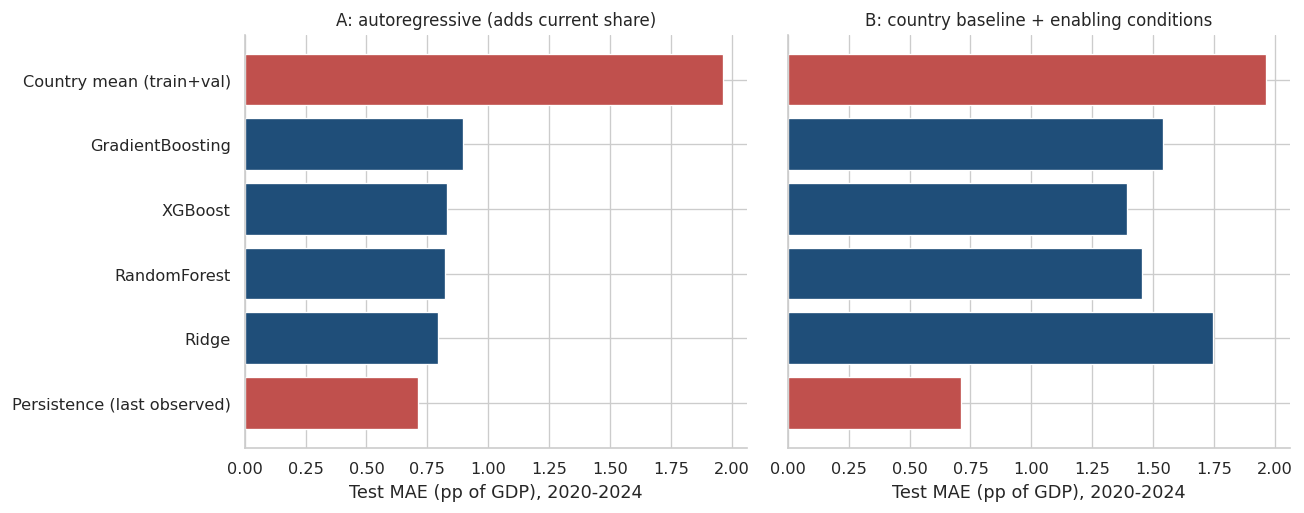

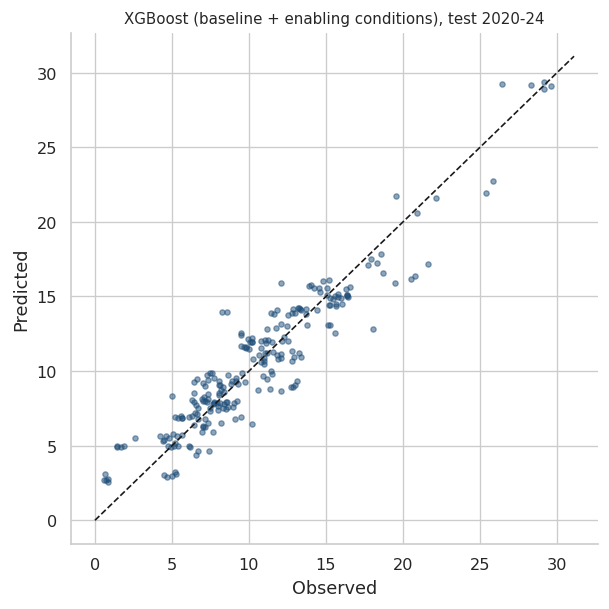

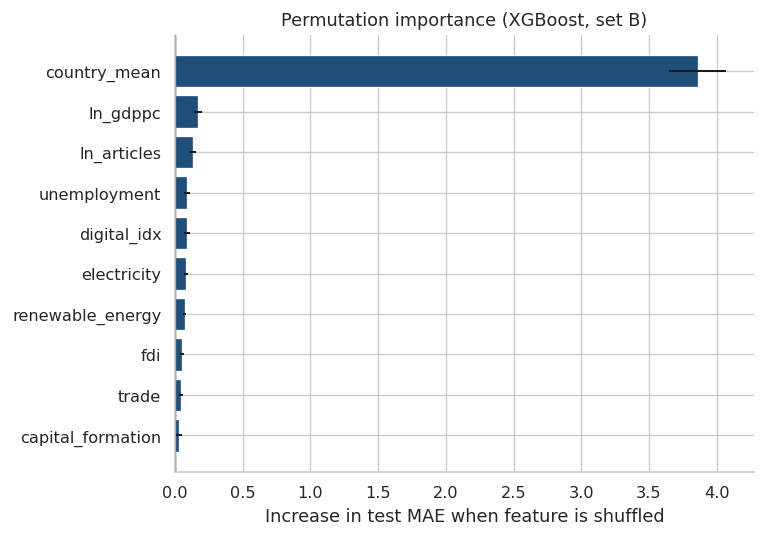

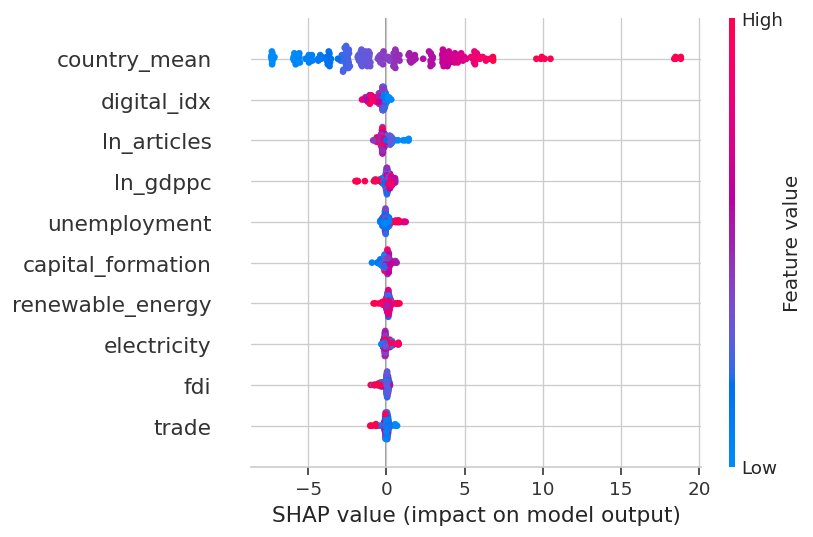

In [7]:
Q = d.sort_values(["country", "year"]).copy()
Q["target"] = Q.groupby("country").manufacturing.shift(-1)
Q["mf_change"] = Q.manufacturing - Q.groupby("country").manufacturing.shift(1)
struct = ["digital_idx", "electricity", "ln_gdppc", "trade", "fdi", "capital_formation", "renewable_energy", "ln_articles", "unemployment"]
sets = {"A: autoregressive (adds current share)": struct + ["manufacturing", "mf_change"], "B: country baseline + enabling conditions": struct + ["country_mean"]}
Q = Q.dropna(subset=["target", "manufacturing"]); Q["ty"] = Q.year + 1
tr, va, te = Q[Q.ty <= 2016].copy(), Q[Q.ty.between(2017, 2019)].copy(), Q[Q.ty >= 2020].copy()
def add_cm(df_, ref):   # country mean of the target, from the fitting window only
    df_["country_mean"] = df_.country.map(ref.groupby("country").target.mean()).fillna(ref.target.mean()); return df_
print("rows train/val/test:", len(tr), len(va), len(te))

def mk(name, **kw):
    est = {"Ridge": lambda: Ridge(**{"alpha": 10, **kw}), "RandomForest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RS, n_jobs=-1, **kw),
           "GradientBoosting": lambda: GradientBoostingRegressor(random_state=RS, **{"n_estimators": 200, "max_depth": 2, "learning_rate": .05, **kw}),
           "XGBoost": lambda: XGBRegressor(random_state=RS, n_jobs=1, verbosity=0, **{"n_estimators": 250, "max_depth": 3, "learning_rate": .05, "subsample": .8, **kw})}[name]()
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", est)])
grids = {"Ridge": [{"alpha": a} for a in (1, 10, 100)], "RandomForest": [{"max_depth": k} for k in (4, 8, None)],
         "GradientBoosting": [{"max_depth": k} for k in (2, 3)], "XGBoost": [{"max_depth": k} for k in (2, 4)]}
mets = lambda y, p: dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** .5, R2=r2_score(y, p))
rows, preds, fitted = [], {}, {}
for sname, feats in sets.items():
    trva = pd.concat([tr, va]); ytest = te.target.values
    tr_, va_, trva_, te_ = add_cm(tr.copy(), tr), add_cm(va.copy(), tr), add_cm(trva.copy(), trva), add_cm(te.copy(), trva)
    base = {"Persistence (last observed)": te.manufacturing.values,
            "Country mean (train+val)": te.country.map(trva.groupby("country").target.mean()).fillna(trva.target.mean()).values}
    for k, p in base.items(): rows.append(dict(feature_set=sname, model=k, **mets(ytest, p))); preds[(sname, k)] = p
    for mname, grid in grids.items():
        best = min(grid, key=lambda kw: mean_absolute_error(va.target, mk(mname, **kw).fit(tr_[feats], tr_.target).predict(va_[feats])))
        mdl = mk(mname, **best).fit(trva_[feats], trva_.target); p = mdl.predict(te_[feats])
        rows.append(dict(feature_set=sname, model=mname, best_params=str(best), **mets(ytest, p))); preds[(sname, mname)] = p; fitted[(sname, mname)] = (mdl, feats)
T = pd.DataFrame(rows)
for sname in sets:                                   # skill relative to the relevant naive benchmark
    ref = T[(T.feature_set == sname) & (T.model == "Persistence (last observed)")].MAE.iloc[0]; T.loc[T.feature_set == sname, "skill_vs_persistence"] = 1 - T.MAE / ref
# country-cluster bootstrap CI for MAE difference vs persistence
def boot_diff(sname, mname, n=500):
    rng = np.random.default_rng(RS); e1 = np.abs(te.target.values - preds[(sname, mname)]); e0 = np.abs(te.target.values - preds[(sname, "Persistence (last observed)")])
    cs = te.country.values; uc = np.unique(cs); idx = {c: np.where(cs == c)[0] for c in uc}; out = []
    for _ in range(n):
        ii = np.concatenate([idx[c] for c in rng.choice(uc, len(uc))]); out.append(e1[ii].mean() - e0[ii].mean())
    return np.percentile(out, [2.5, 97.5])
for i, r in T.iterrows():
    if r.model not in ("Persistence (last observed)",):
        lo, hi = boot_diff(r.feature_set, r.model); T.loc[i, ["dMAE_lo", "dMAE_hi"]] = [lo, hi]
T.round(3).to_csv("results/table_prediction_metrics.csv", index=False); print(T.round(3).drop(columns="best_params", errors="ignore").to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for a_, (sname, _) in zip(ax, sets.items()):
    t = T[T.feature_set == sname].sort_values("MAE"); a_.barh(t.model, t.MAE, color=[C2 if "Persist" in m_ or "mean" in m_ else C1 for m_ in t.model]); a_.set_title(sname, fontsize=10); a_.set_xlabel("Test MAE (pp of GDP), 2020-2024")
plt.tight_layout(); plt.savefig("results/fig9_prediction_mae.png"); plt.show()

sB = list(sets)[1]; trees = ["RandomForest", "GradientBoosting", "XGBoost"]
best_B = T[(T.feature_set == sB) & T.model.isin(trees)].sort_values("MAE").model.iloc[0]
teB = add_cm(te.copy(), pd.concat([tr, va]))
fig, ax = plt.subplots(figsize=(5.2, 5.2)); ax.scatter(te.target, preds[(sB, best_B)], s=10, alpha=.5, color=C1); lim = [0, max(te.target.max(), preds[(sB, best_B)].max()) * 1.05]
ax.plot(lim, lim, "k--", lw=1); ax.set_xlabel("Observed"); ax.set_ylabel("Predicted"); ax.set_title(f"{best_B} (baseline + enabling conditions), test 2020-24", fontsize=9); plt.tight_layout(); plt.savefig("results/fig10_pred_vs_actual.png"); plt.show()

# descriptive importance (not causal): permutation importance on the test set, SHAP for tree models
mdl, feats = fitted[(sB, best_B)]
pi = permutation_importance(mdl, teB[feats], teB.target, scoring="neg_mean_absolute_error", n_repeats=30, random_state=RS)
imp = pd.DataFrame({"feature": feats, "mean": pi.importances_mean, "sd": pi.importances_std}).sort_values("mean"); imp.round(4).to_csv("results/table_permutation_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(6.5, 4.6)); ax.barh(imp.feature, imp["mean"], xerr=imp["sd"], color=C1); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("Increase in test MAE when feature is shuffled"); ax.set_title(f"Permutation importance ({best_B}, set B)"); plt.tight_layout(); plt.savefig("results/fig11_permutation_importance.png"); plt.show()
try:
    import shap
    Xt = pd.DataFrame(mdl[:-1].transform(teB[feats]), columns=feats); ex = shap.TreeExplainer(mdl[-1]); sv = ex.shap_values(Xt)
    shap.summary_plot(sv, Xt, show=False, plot_size=(7, 4.6)); plt.tight_layout(); plt.savefig("results/fig12_shap_summary.png", dpi=300); plt.show()
except Exception as e:
    print("SHAP skipped:", e)


## 7. Scenario-matrix placement (needs a governance series)

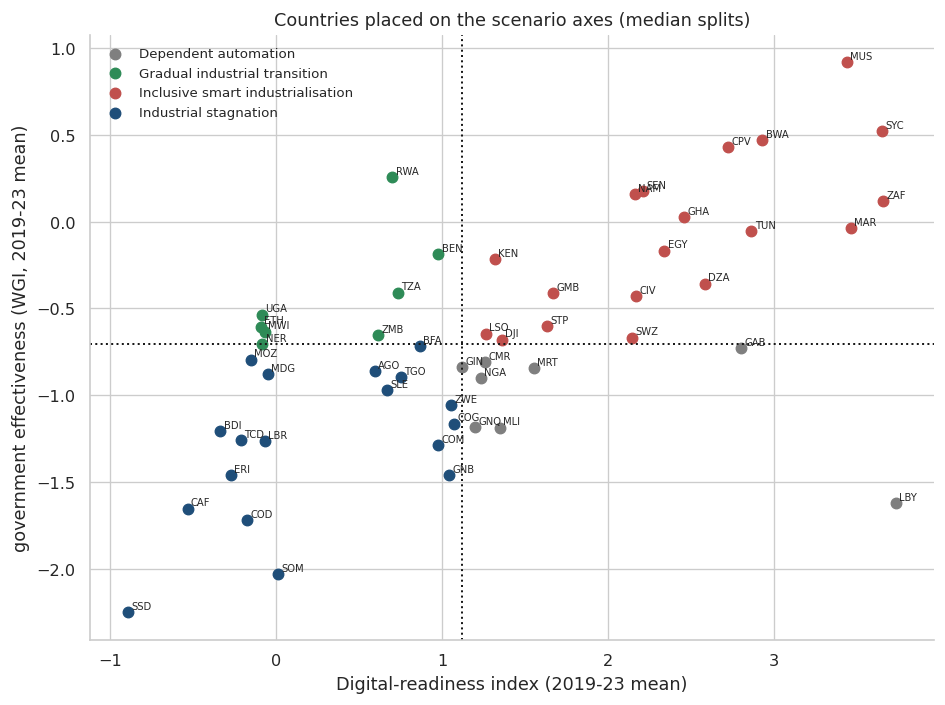

Done. Outputs in results/


In [8]:
gcol = next((c for c in ("government_effectiveness", "regulatory_quality") if c in d.columns and d[c].notna().sum() > 300), None)
if gcol:
    rec = d[d.year.between(2019, 2023)].groupby("country").agg(dig=("digital_idx", "mean"), gov=(gcol, "mean")).dropna()
    xm, ym = rec.dig.median(), rec.gov.median(); rec["quadrant"] = np.where(rec.gov >= ym, np.where(rec.dig >= xm, "Inclusive smart industrialisation", "Gradual industrial transition"),
                                                                         np.where(rec.dig >= xm, "Dependent automation", "Industrial stagnation"))
    rec.round(3).to_csv("results/table_scenario_placement.csv")
    fig, ax = plt.subplots(figsize=(8, 6)); pal = dict(zip(rec.quadrant.unique(), [C1, C3, C2, C4]))
    for q, g_ in rec.groupby("quadrant"): ax.scatter(g_.dig, g_.gov, label=q, color=pal[q], s=40)
    for c, r in rec.iterrows(): ax.annotate(c, (r.dig, r.gov), fontsize=6, xytext=(2, 2), textcoords="offset points")
    ax.axvline(xm, color="k", ls=":"); ax.axhline(ym, color="k", ls=":"); ax.set_xlabel("Digital-readiness index (2019-23 mean)"); ax.set_ylabel(f"{gcol.replace('_', ' ')} (WGI, 2019-23 mean)")
    ax.legend(frameon=False, fontsize=8); ax.set_title("Countries placed on the scenario axes (median splits)"); plt.tight_layout(); plt.savefig("results/fig13_scenario_placement.png"); plt.show()
else:
    print("No governance series retrieved: download the WGI file manually and merge it as 'government_effectiveness'.")
print("Done. Outputs in results/")


rows  train / validation / test: 743 144 232

=== TABLE 4: test-set accuracy 2020-2024 (dMAE = MAE minus persistence MAE, 95% CI; negative = better) ===
                   feature_set            model   MAE  RMSE    R2  skill_vs_persistence  dMAE_lo  dMAE_hi
             A: autoregressive      Persistence 0.712 1.079 0.958                 0.000      NaN      NaN
             A: autoregressive     Country mean 1.964 2.503 0.772                -1.757    0.857    1.610
             A: autoregressive            Ridge 0.792 1.137 0.953                -0.112    0.026    0.136
             A: autoregressive     RandomForest 0.822 1.189 0.948                -0.154    0.018    0.229
             A: autoregressive GradientBoosting 0.896 1.312 0.937                -0.258    0.080    0.309
             A: autoregressive          XGBoost 0.829 1.213 0.946                -0.163    0.022    0.243
B: country baseline + enabling      Persistence 0.712 1.079 0.958                 0.000      NaN      NaN

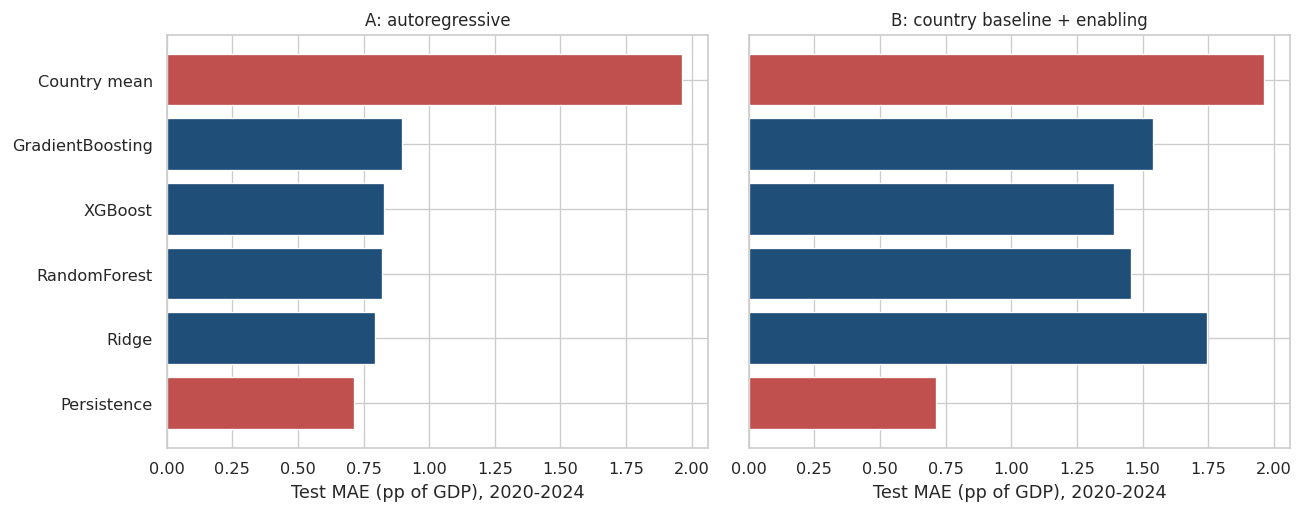


=== Permutation importance, XGBoost, set B ===
           feature   mean     sd
     country_mean 3.8606 0.2122
         ln_gdppc 0.1689 0.0299
      ln_articles 0.1289 0.0240
     unemployment 0.0862 0.0223
      digital_idx 0.0860 0.0217
      electricity 0.0804 0.0169
 renewable_energy 0.0713 0.0127
              fdi 0.0542 0.0143
            trade 0.0437 0.0164
capital_formation 0.0283 0.0207


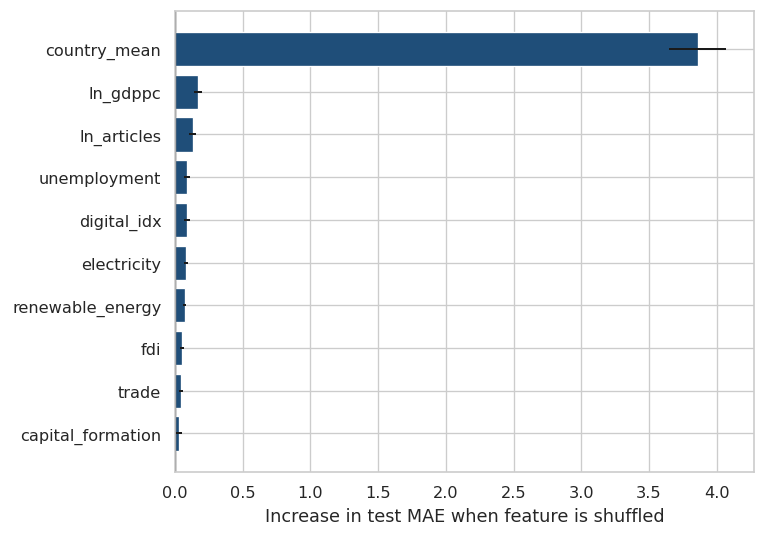

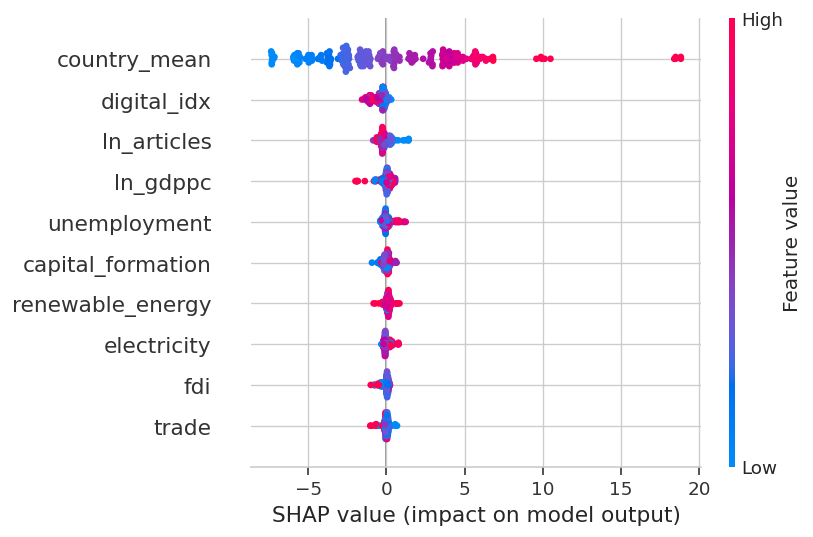


Governance column used: government_effectiveness
Median splits: readiness = 1.12, governance = -0.71  (n = 53 countries)

=== Countries per scenario ===
Dependent automation (8): CMR, GAB, GIN, GNQ, LBY, MLI, MRT, NGA
Gradual industrial transition (8): BEN, ETH, MWI, NER, RWA, TZA, UGA, ZMB
Inclusive smart industrialisation (19): BWA, CIV, CPV, DJI, DZA, EGY, GHA, GMB, KEN, LSO, MAR, MUS, NAM, SEN, STP, SWZ, SYC, TUN, ZAF
Industrial stagnation (18): AGO, BDI, BFA, CAF, COD, COG, COM, ERI, GNB, LBR, MDG, MOZ, SLE, SOM, SSD, TCD, TGO, ZWE


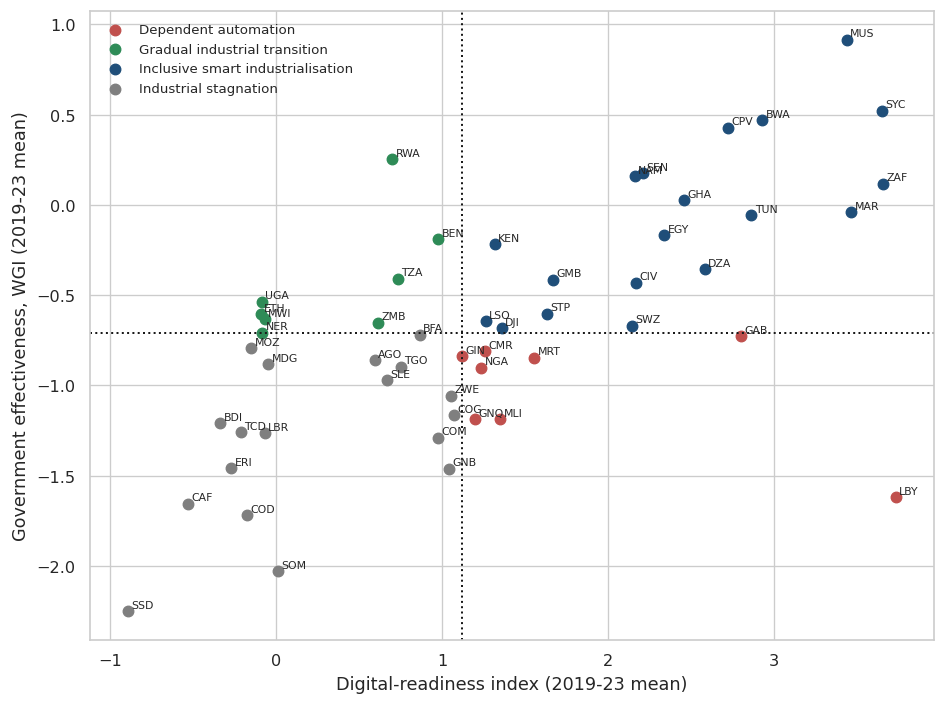

In [9]:
# ===== Section 4.6 standalone: forecasting test + scenario placement =====
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
warnings.filterwarnings("ignore"); os.makedirs("results", exist_ok=True)
RS = 42; C1, C2, C3, C4 = "#1f4e79", "#c0504d", "#2e8b57", "#7f7f7f"
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

# ---- 1. rebuild variables exactly as in the main notebook ----
d = pd.read_csv("results/africa_panel_raw.csv").sort_values(["country", "year"]).reset_index(drop=True)
d["ln_gdppc"] = np.log(d.gdp_per_capita); d["ln_articles"] = np.log1p(d.scientific_articles)
for c in ["internet", "mobile", "electricity", "fdi", "trade", "capital_formation", "renewable_energy", "unemployment", "ln_articles"]:
    lo, hi = d[c].quantile([.01, .99]); d[c] = d[c].clip(lo, hi)
dr = d[["internet", "mobile"]].dropna(); Z = StandardScaler().fit(dr); pca = PCA(1, random_state=RS).fit(Z.transform(dr))
d["digital_idx"] = np.nan
d.loc[dr.index, "digital_idx"] = pca.transform(Z.transform(dr))[:, 0] * np.sign(pca.components_[0].sum())

# ---- 2. forecasting data: target = manufacturing share in t+1 ----
Q = d.copy()
Q["target"] = Q.groupby("country").manufacturing.shift(-1)
Q["mf_change"] = Q.manufacturing - Q.groupby("country").manufacturing.shift(1)
struct = ["digital_idx", "electricity", "ln_gdppc", "trade", "fdi", "capital_formation", "renewable_energy", "ln_articles", "unemployment"]
SETS = {"A: autoregressive": struct + ["manufacturing", "mf_change"], "B: country baseline + enabling": struct + ["country_mean"]}
Q = Q.dropna(subset=["target", "manufacturing"]).copy(); Q["ty"] = Q.year + 1
tr, va, te = Q[Q.ty <= 2016].copy(), Q[Q.ty.between(2017, 2019)].copy(), Q[Q.ty >= 2020].copy()
print("rows  train / validation / test:", len(tr), len(va), len(te))
def add_cm(df_, ref):
    df_["country_mean"] = df_.country.map(ref.groupby("country").target.mean()).fillna(ref.target.mean()); return df_

def mk(name, **kw):
    est = {"Ridge": lambda: Ridge(**{"alpha": 10, **kw}),
           "RandomForest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RS, n_jobs=-1, **kw),
           "GradientBoosting": lambda: GradientBoostingRegressor(random_state=RS, **{"n_estimators": 200, "max_depth": 2, "learning_rate": .05, **kw}),
           "XGBoost": lambda: XGBRegressor(random_state=RS, n_jobs=1, verbosity=0, **{"n_estimators": 250, "max_depth": 3, "learning_rate": .05, "subsample": .8, **kw})}[name]()
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", est)])
GRID = {"Ridge": [{"alpha": a} for a in (1, 10, 100)], "RandomForest": [{"max_depth": k} for k in (4, 8, None)],
        "GradientBoosting": [{"max_depth": k} for k in (2, 3)], "XGBoost": [{"max_depth": k} for k in (2, 4)]}
mets = lambda y, p: dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** .5, R2=r2_score(y, p))

rows, preds, fitted = [], {}, {}
trva = pd.concat([tr, va]); ytest = te.target.values
for sname, feats in SETS.items():
    tr_, va_, trva_, te_ = add_cm(tr.copy(), tr), add_cm(va.copy(), tr), add_cm(trva.copy(), trva), add_cm(te.copy(), trva)
    base = {"Persistence": te.manufacturing.values,
            "Country mean": te.country.map(trva.groupby("country").target.mean()).fillna(trva.target.mean()).values}
    for k, p in base.items(): rows.append(dict(feature_set=sname, model=k, **mets(ytest, p))); preds[(sname, k)] = p
    for mname, grid in GRID.items():
        best = min(grid, key=lambda kw: mean_absolute_error(va_.target, mk(mname, **kw).fit(tr_[feats], tr_.target).predict(va_[feats])))
        mdl = mk(mname, **best).fit(trva_[feats], trva_.target); p = mdl.predict(te_[feats])
        rows.append(dict(feature_set=sname, model=mname, best_params=str(best), **mets(ytest, p))); preds[(sname, mname)] = p; fitted[(sname, mname)] = (mdl, feats, te_)
T = pd.DataFrame(rows)
for sname in SETS:
    ref = T[(T.feature_set == sname) & (T.model == "Persistence")].MAE.iloc[0]
    T.loc[T.feature_set == sname, "skill_vs_persistence"] = 1 - T.MAE / ref

def boot_diff(sname, mname, n=500):   # country-cluster bootstrap of MAE(model) - MAE(persistence)
    rng = np.random.default_rng(RS); e1 = np.abs(ytest - preds[(sname, mname)]); e0 = np.abs(ytest - preds[(sname, "Persistence")])
    cs = te.country.values; uc = np.unique(cs); idx = {c: np.where(cs == c)[0] for c in uc}; out = []
    for _ in range(n):
        ii = np.concatenate([idx[c] for c in rng.choice(uc, len(uc))]); out.append(e1[ii].mean() - e0[ii].mean())
    return np.percentile(out, [2.5, 97.5])
for i, r in T.iterrows():
    if r.model != "Persistence": T.loc[i, ["dMAE_lo", "dMAE_hi"]] = boot_diff(r.feature_set, r.model)
T.round(3).to_csv("results/table_prediction_metrics.csv", index=False)
print("\n=== TABLE 4: test-set accuracy 2020-2024 (dMAE = MAE minus persistence MAE, 95% CI; negative = better) ===")
print(T.drop(columns="best_params", errors="ignore").round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for a_, sname in zip(ax, SETS):
    t = T[T.feature_set == sname].sort_values("MAE")
    a_.barh(t.model, t.MAE, color=[C2 if m in ("Persistence", "Country mean") else C1 for m in t.model]); a_.set_title(sname, fontsize=10); a_.set_xlabel("Test MAE (pp of GDP), 2020-2024")
plt.tight_layout(); plt.savefig("results/fig9_prediction_mae.png", dpi=300); plt.show()

# ---- 3. which inputs does the best set-B tree model use? (descriptive, not causal) ----
sB = list(SETS)[1]; trees = ["RandomForest", "GradientBoosting", "XGBoost"]
bestB = T[(T.feature_set == sB) & T.model.isin(trees)].sort_values("MAE").model.iloc[0]
mdl, feats, teB = fitted[(sB, bestB)]
pi = permutation_importance(mdl, teB[feats], teB.target, scoring="neg_mean_absolute_error", n_repeats=30, random_state=RS)
imp = pd.DataFrame({"feature": feats, "mean": pi.importances_mean, "sd": pi.importances_std}).sort_values("mean", ascending=False)
imp.round(4).to_csv("results/table_permutation_importance.csv", index=False)
print(f"\n=== Permutation importance, {bestB}, set B ===\n", imp.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 4.6)); i2 = imp.sort_values("mean")
ax.barh(i2.feature, i2["mean"], xerr=i2["sd"], color=C1); ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Increase in test MAE when feature is shuffled")
plt.tight_layout(); plt.savefig("results/fig11_permutation_importance.png", dpi=300); plt.show()
try:
    import shap
    Xt = pd.DataFrame(mdl[:-1].transform(teB[feats]), columns=feats); sv = shap.TreeExplainer(mdl[-1]).shap_values(Xt)
    shap.summary_plot(sv, Xt, show=False, plot_size=(7, 4.6)); plt.tight_layout(); plt.savefig("results/fig12_shap_summary.png", dpi=300); plt.show()
except Exception as e: print("SHAP skipped:", e)

# ---- 4. scenario placement: readiness index x government effectiveness ----
gcol = next((c for c in ("government_effectiveness", "regulatory_quality") if c in d.columns and d[c].notna().sum() > 300), None)
print("\nGovernance column used:", gcol)
rec = d[d.year.between(2019, 2023)].groupby("country").agg(readiness=("digital_idx", "mean"), governance=(gcol, "mean")).dropna()
xm, ym = rec.readiness.median(), rec.governance.median()
rec["scenario"] = np.where(rec.governance >= ym, np.where(rec.readiness >= xm, "Inclusive smart industrialisation", "Gradual industrial transition"),
                           np.where(rec.readiness >= xm, "Dependent automation", "Industrial stagnation"))
rec.round(3).sort_values("scenario").to_csv("results/table_scenario_placement.csv")
print(f"Median splits: readiness = {xm:.2f}, governance = {ym:.2f}  (n = {len(rec)} countries)")
print("\n=== Countries per scenario ===")
for s_, g_ in rec.groupby("scenario"): print(f"{s_} ({len(g_)}): {', '.join(sorted(g_.index))}")
pal = {"Inclusive smart industrialisation": C1, "Gradual industrial transition": C3, "Dependent automation": C2, "Industrial stagnation": C4}
fig, ax = plt.subplots(figsize=(8, 6))
for q, g_ in rec.groupby("scenario"): ax.scatter(g_.readiness, g_.governance, label=q, color=pal[q], s=40)
for c, r in rec.iterrows(): ax.annotate(c, (r.readiness, r.governance), fontsize=6.5, xytext=(2, 2), textcoords="offset points")
ax.axvline(xm, color="k", ls=":"); ax.axhline(ym, color="k", ls=":")
ax.set_xlabel("Digital-readiness index (2019-23 mean)"); ax.set_ylabel("Government effectiveness, WGI (2019-23 mean)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.savefig("results/fig13_scenario_placement.png", dpi=300); plt.show()